# 05 · Modules — hub cross-repression (Gate 3)
On the hub, correlate every Gast-OR-pSom gene with the Gast and pSom module scores. If the two programs compete (cross-repression), Gast-loading genes anti-correlate with pSom-loading genes — a **negative** mutual correlation *r*.

**Gate 3 (branching only):** is the hub Gast↔pSom correlation negative?

In [1]:
import os
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
from adjustText import adjust_text
sc.settings.verbosity = 1

In [2]:
name = os.path.split(os.getcwd())[1]
cat  = os.path.split(os.path.split(os.getcwd())[0])[1]
pth  = os.path.join(*(['..']*4))
pth_data = os.path.join(pth, 'data')
pth_in   = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_feat = os.path.join(pth_data, 'features', 'biomart')
pth_out  = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)

In [3]:
c_dict = {'Gast': plt.cm.tab20c(12), 'pSom': plt.cm.tab20c(8), 'Both': 'darkgrey'}

In [4]:
# load signatures data from h5ad file
adata = sc.read_h5ad(os.path.join(pth_in, 'signatures.h5ad')); adata

In [5]:
# select module genes — Gast OR pSom
get_feat = lambda p: pd.read_csv(p).hsapiens
gast = get_feat(os.path.join(pth_feat, 'GSE162534.csv'))
psom = get_feat(os.path.join(pth_feat, 'GSE229103.csv'))
g = pd.merge(gast, psom, 'outer').hsapiens.drop_duplicates()
g = g.loc[g.isin(adata.var_names)]

In [6]:
# select the hub — basal convergence population
msk = (adata.obs.celltype == 'Basal')
adata_plt = adata[msk, g].copy(); adata_plt

In [7]:
# per-gene correlation with each module -> rank by |loading|
X = pd.DataFrame(adata_plt.X.toarray(), index = adata_plt.obs_names, columns = g)
X = X.loc[:, (X.nunique(axis = 0) > 1)].copy()
R = pd.DataFrame(index = X.columns)
mod1 = adata_plt.obs.Gast.values[:, None]
mod2 = adata_plt.obs.pSom.values[:, None]
R['Gast'] = pearsonr(X, mod1, axis = 0).statistic
R['pSom'] = pearsonr(X, mod2, axis = 0).statistic
rank = R.abs().sum(axis = 1).rank(ascending = False)
R = R.loc[rank.sort_values().index].copy()

In [8]:
# assign module labels — Gast | pSom | Both
gs, ps = set(gast), set(psom)
ix = R.index
msk_dict = {'Gast': ix.isin(gs) & ~ix.isin(ps),
            'pSom': ~ix.isin(gs) & ix.isin(ps),
            'Both': ix.isin(gs) & ix.isin(ps)}
for mod, m in msk_dict.items():
    R.loc[m, 'Module'] = mod
    print(mod, int(m.sum()))
R['Module'] = pd.Categorical(R.Module, list(reversed(list(msk_dict.keys()))), ordered = True)

Gast 51
pSom 63
Both 24


In [9]:
# module mutual correlation (exclude genes in BOTH modules)
rval = np.corrcoef(*R.loc[~msk_dict['Both'], ['Gast', 'pSom']].values.T)[0, 1].round(2)
print('hub Gast<->pSom module r =', rval)

hub Gast<->pSom module r = -0.38


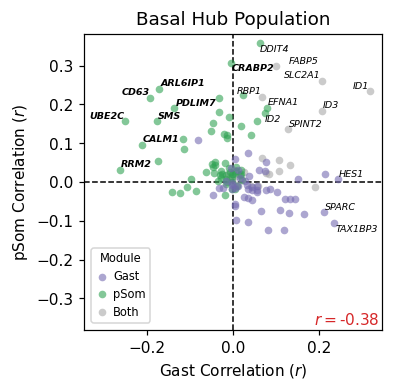

In [10]:
# plot gene-module correlations — scatter
fig, ax = plt.subplots(1, 1, figsize = (3.5, 3.5))
for mod, sdf in R.groupby('Module', observed = True):
    sdf.plot(kind = 'scatter', x = 'Gast', y = 'pSom', color = c_dict[mod], label = mod,
             s = 25, alpha = .6, linewidth = 0, ax = ax)
ax.axvline(0, color = 'k', lw = 1, ls = '--', zorder = 0)
ax.axhline(0, color = 'k', lw = 1, ls = '--', zorder = 0)
xlim = abs(np.asarray(ax.get_xlim())).max(); ylim = abs(np.asarray(ax.get_ylim())).max()
ax.set_xlim(-xlim, xlim); ax.set_ylim(-ylim, ylim)
n, texts = 20, list()
for i in R.head(n).index:
    xi, yi = R.loc[i].Gast, R.loc[i].pSom
    fw = 'bold' if (xi < 0 and yi > 0) else 'normal'
    texts.append(ax.text(xi, yi, i, fontsize = 6.25, fontstyle = 'italic', fontweight = fw))
adjust_text(texts = texts)
ax.legend(title = 'Module', loc = 'lower left', title_fontsize = 7.5, handlelength = 1,
          handletextpad = .5, borderaxespad = .65, fontsize = 7.5, reverse = True)
ax.text(.99, .01, r'$r=$' + f'{rval}', transform = ax.transAxes, fontsize = 10,
        color = 'tab:red', ha = 'right', va = 'bottom')
ax.set_title('Basal Hub Population')
ax.set_xlabel(r'Gast Correlation ($r$)'); ax.set_ylabel(r'pSom Correlation ($r$)')
fig.savefig(os.path.join(pth_out, 'modules.pdf'), bbox_inches = 'tight')

The Gast-loading and pSom-loading genes sit in opposite quadrants of the hub population: mutual **r = -0.38** (Puram anchor -0.49; Filbin branching case -0.34) — competitive Gast↔pSom cross-repression at the branch point. **Gate 3 GO.**